# 03 · Análise temporal

Responde às perguntas centrais do projeto:

1. **Quando a IA virou tendência?** Qual a fração de trabalhos que citam IA em cada ano, e em
   que ano o crescimento acelerou.
2. **Quais temas ganharam e perderam espaço** entre o começo e o fim do período.
3. **Há diferença entre mestrado e doutorado, e entre regiões?**

Usa os tópicos do notebook 02 e o léxico de IA de `src/lexico_ia.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

sys.path.append("../src")
from lexico_ia import familias_citadas

PROCESSADOS = Path("../data/processed")
FIGURAS = Path("../reports/figures")
RELATORIOS = Path("../reports")

TINTA = "#52514e"
AZUL, LARANJA, VERDE, VERMELHO = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA, "xtick.color": TINTA,
    "ytick.color": TINTA, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e8e7e3", "font.size": 10,
})

trabalhos = pd.read_csv(PROCESSADOS / "topicos_bertopic.csv.gz")
textos = pd.read_csv(PROCESSADOS / "resumos_preprocessados.csv.gz", usecols=["texto_limpo"])
print(f"{len(trabalhos)} trabalhos com tópico atribuído")

23007 trabalhos com tópico atribuído


## Marcando os trabalhos de IA

O notebook 02 mostrou que a IA não forma um tópico próprio: ela aparece dentro de temas de
aplicação. Por isso cada resumo é marcado pelo léxico de `src/lexico_ia.py`, que separa os termos
em três famílias, correspondentes a fases da área: **aprendizado de máquina** (termos gerais e
métodos clássicos), **aprendizado profundo** e **modelos de linguagem**.

In [2]:
familias = pd.DataFrame(
    [familias_citadas(t) for t in textos.loc[trabalhos["id"], "texto_limpo"]],
    index=trabalhos.index,
)
trabalhos = pd.concat([trabalhos, familias], axis=1)
trabalhos["ia"] = familias.any(axis=1)

trabalhos.to_csv(PROCESSADOS / "ia_lexico.csv.gz", index=False, compression="gzip")
print(f"{trabalhos['ia'].mean():.0%} dos trabalhos citam algum termo de IA")

21% dos trabalhos citam algum termo de IA


## 1. Quando a IA virou tendência

In [3]:
por_ano = trabalhos.groupby("ano")["ia"].mean() * 100
anos, valores = por_ano.index.to_numpy(), por_ano.to_numpy()

def ajustar_duas_fases(ano_corte):
    retas, erro = [], 0
    for trecho in (anos < ano_corte, anos >= ano_corte):
        coef = np.polyfit(anos[trecho], valores[trecho], 1)
        erro += ((np.polyval(coef, anos[trecho]) - valores[trecho]) ** 2).sum()
        retas.append(coef)
    return erro, retas

candidatos = range(anos.min() + 3, anos.max() - 2)  # pelo menos 3 anos em cada fase
virada = min(candidatos, key=lambda ano: ajustar_duas_fases(ano)[0])
_, (antes, depois) = ajustar_duas_fases(virada)
print(f"Ponto de virada: {virada}")
print(f"Antes: +{antes[0]:.1f} ponto percentual por ano | Depois: +{depois[0]:.1f} p.p. por ano")

Ponto de virada: 2018
Antes: +0.8 ponto percentual por ano | Depois: +3.8 p.p. por ano


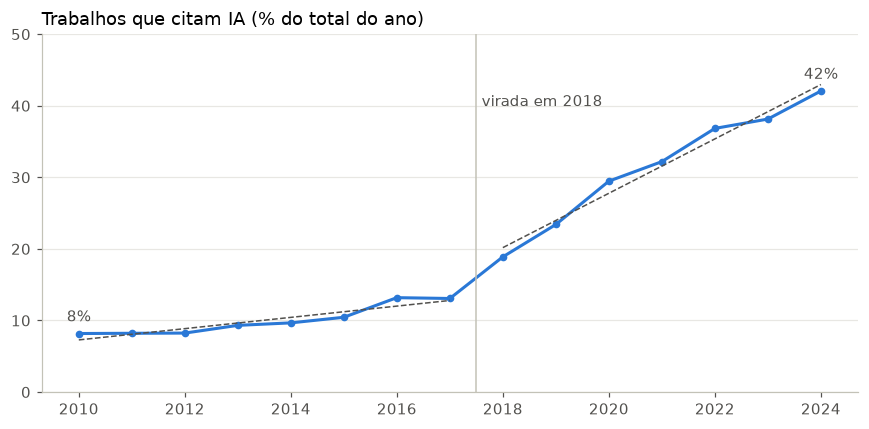

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(anos, valores, color=AZUL, linewidth=2, marker="o", markersize=4)
for coef, trecho in ((antes, anos < virada), (depois, anos >= virada)):
    ax.plot(anos[trecho], np.polyval(coef, anos[trecho]), color=TINTA, linewidth=1, linestyle="--")
ax.axvline(virada - 0.5, color="#c3c2b7", linewidth=1)
ax.annotate(f"virada em {virada}", (virada - 0.4, valores.max() * 0.95), color=TINTA)
for ano in (anos[0], anos[-1]):
    ax.annotate(f"{por_ano[ano]:.0f}%", (ano, por_ano[ano]), xytext=(0, 8),
                textcoords="offset points", ha="center", color=TINTA)
ax.set_title("Trabalhos que citam IA (% do total do ano)", loc="left", fontsize=12)
ax.set_xticks(anos[::2])
ax.set_ylim(0, 50)
fig.tight_layout()
fig.savefig(FIGURAS / "ia_por_ano.png", bbox_inches="tight")

ano,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
aprendizado_maquina,8.2,8.2,8.2,9.3,9.6,10.4,13.1,12.9,18.3,22.2,27.3,29.4,33.5,34.7,36.5
aprendizado_profundo,0.0,0.1,0.0,0.2,0.3,0.4,0.8,1.9,4.3,7.7,10.2,9.9,12.4,12.1,12.0
modelos_linguagem,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.1,0.1,0.7,1.6,2.1,3.9,6.7


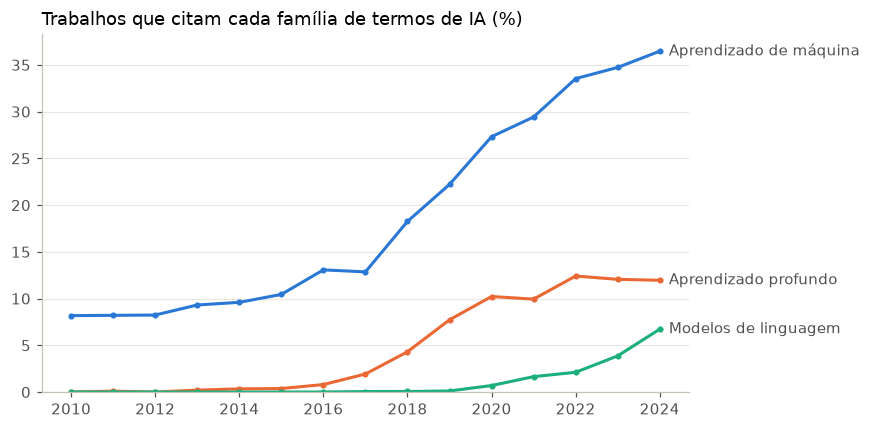

In [5]:
por_familia = trabalhos.groupby("ano")[list(familias.columns)].mean() * 100
nomes = {"aprendizado_maquina": "Aprendizado de máquina",
         "aprendizado_profundo": "Aprendizado profundo",
         "modelos_linguagem": "Modelos de linguagem"}
cores = {"aprendizado_maquina": AZUL, "aprendizado_profundo": LARANJA, "modelos_linguagem": VERDE}

fig, ax = plt.subplots(figsize=(8, 4))
for familia, serie in por_familia.items():
    ax.plot(serie.index, serie.values, color=cores[familia], linewidth=2, marker="o", markersize=3)
    ax.annotate(nomes[familia], (serie.index[-1], serie.values[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=TINTA)
ax.set_title("Trabalhos que citam cada família de termos de IA (%)", loc="left", fontsize=12)
ax.set_xticks(anos[::2])
ax.set_ylim(0)
fig.tight_layout()
fig.savefig(FIGURAS / "ia_familias.png", bbox_inches="tight")
por_familia.round(1).T

As famílias mostram três ondas: o aprendizado de máquina cresce durante todo o período; o
aprendizado profundo aparece por volta de 2017 e se estabiliza nos últimos anos; e os modelos de
linguagem (transformers, LLMs) começam em 2020 e são a família que mais cresce no fim da série.
Um trabalho pode citar mais de uma família.

## 2. Temas que ganharam e perderam espaço

Para cada tópico, compara a fatia dos trabalhos que ele ocupa no começo (2010–2014) e no fim
(2020–2024) do período. Usar fatias, e não contagens, evita que um tópico pareça crescer só porque
o total de trabalhos cresceu.

In [6]:
info = pd.read_csv(RELATORIOS / "topicos_bertopic.csv").set_index("tópico")
rotulos = info["palavras"].str.split(", ").str[:3].str.join(", ")

inicio = trabalhos.query("ano <= 2014")["topico"].value_counts(normalize=True)
fim = trabalhos.query("ano >= 2020")["topico"].value_counts(normalize=True)
variacao = (fim.reindex(info.index, fill_value=0) - inicio.reindex(info.index, fill_value=0)) * 100

mudancas = pd.DataFrame({"rótulo": rotulos, "variação (p.p.)": variacao.round(2),
                         "2010–2014 (%)": (inicio.reindex(info.index, fill_value=0) * 100).round(1),
                         "2020–2024 (%)": (fim.reindex(info.index, fill_value=0) * 100).round(1)})
mudancas = mudancas.sort_values("variação (p.p.)")
mudancas.to_csv(RELATORIOS / "variacao_topicos.csv")
destaque = pd.concat([mudancas.head(8), mudancas.tail(8)])
destaque

,rótulo,variação (p.p.),2010–2014 (%),2020–2024 (%)
tópico,,,,
1,"ágel, refatoração, dívida",-3.49,8.9,5.4
2,"chip, thread, quântico",-2.92,5.5,2.5
11,"intervalar, quântico, empacotamento",-2.51,4.8,2.3
4,"segmentação imagem, renderização, pose",-1.50,4.2,2.7
29,"rssf, sensor fio, fio rssf",-1.34,1.9,0.6
56,"televisão, televisão digital, aplicação intera...",-1.25,1.3,0.1
44,"composição serviço, soa, restful",-1.24,1.6,0.4
13,"governança, bpm, modelo negócio",-1.16,3.3,2.2
23,"malicioso, intrusão, cibernético",1.02,1.2,2.2


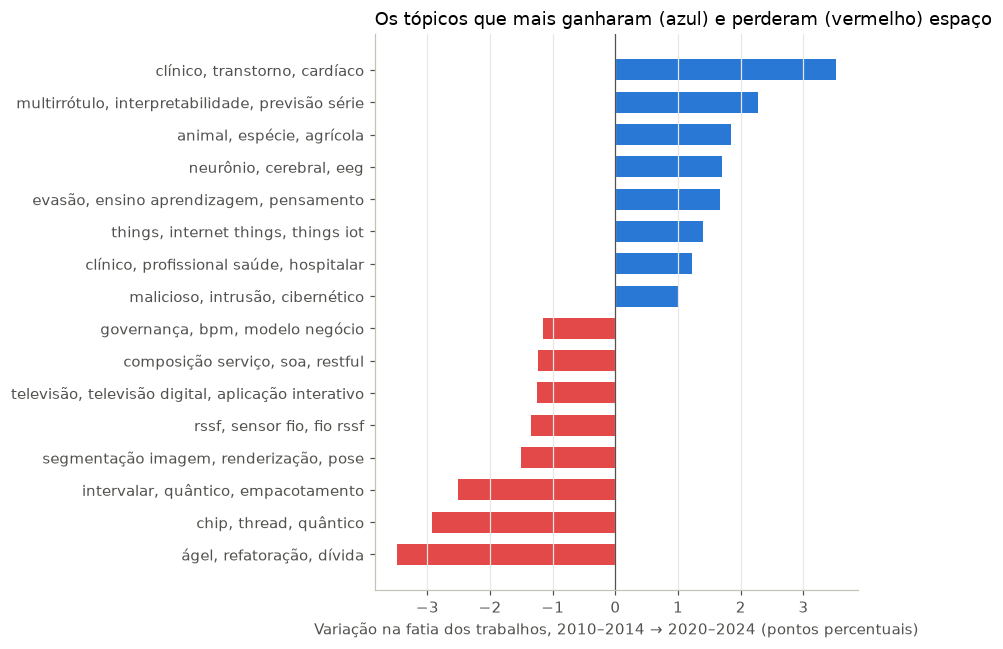

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
cores_barras = [VERMELHO if v < 0 else AZUL for v in destaque["variação (p.p.)"]]
ax.barh(destaque["rótulo"], destaque["variação (p.p.)"], color=cores_barras, height=0.65)
ax.axvline(0, color=TINTA, linewidth=0.8)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True, color="#e8e7e3")
ax.set_xlabel("Variação na fatia dos trabalhos, 2010–2014 → 2020–2024 (pontos percentuais)")
ax.set_title("Os tópicos que mais ganharam (azul) e perderam (vermelho) espaço",
             loc="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURAS / "variacao_topicos.png", bbox_inches="tight")

## 3. Mestrado × doutorado e regiões

O teste **qui-quadrado** verifica se a proporção de trabalhos de IA depende do grupo (grau ou
região) ou se as diferenças observadas poderiam ser só acaso. Um *p-valor* abaixo de 0,05 indica
diferença estatisticamente significativa. O teste é feito no período todo e só nos anos recentes
(2020–2024), porque a mistura de anos pode esconder ou criar diferenças.

In [8]:
def teste_ia(dados, grupo):
    tabela = pd.crosstab(dados[grupo], dados["ia"])
    _, p, _, _ = chi2_contingency(tabela)
    proporcao = (tabela[True] / tabela.sum(axis=1) * 100).round(1)
    return proporcao, p

graus = ["Mestrado", "Doutorado", "Mestrado Profissional"]  # doutorado profissional: só 14 casos
academicos = trabalhos[trabalhos["grau"].isin(graus)]
recentes = academicos.query("ano >= 2020")

linhas = []
for nome, dados in (("2010–2024", academicos), ("2020–2024", recentes)):
    proporcao, p = teste_ia(dados, "grau")
    linhas.append({"período": nome, **proporcao.to_dict(), "p-valor": f"{p:.4f}"})
pd.DataFrame(linhas).set_index("período")

,Doutorado,Mestrado,Mestrado Profissional,p-valor
período,,,,
2010–2024,23.1,20.4,17.5,0.0000
2020–2024,35.1,36.7,31.6,0.0183


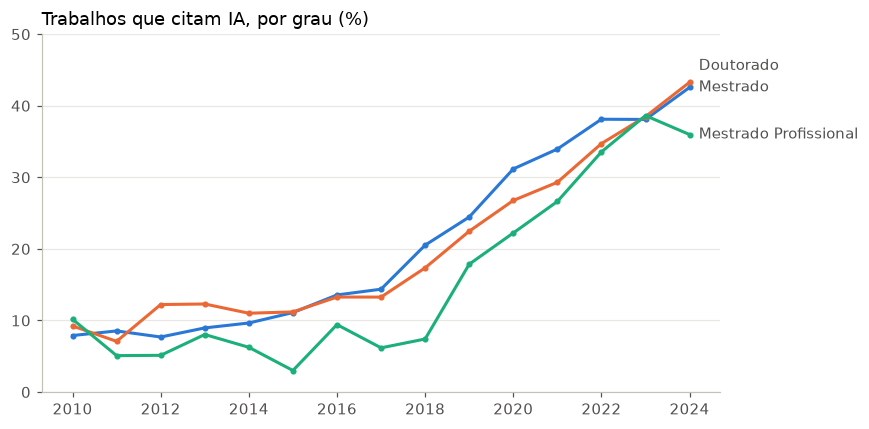

In [9]:
por_grau = academicos.groupby(["ano", "grau"])["ia"].mean().unstack() * 100
cores_grau = {"Mestrado": AZUL, "Doutorado": LARANJA, "Mestrado Profissional": VERDE}

fig, ax = plt.subplots(figsize=(8, 4))
# Afasta os rótulos do fim das linhas quando os valores finais são muito próximos
finais = por_grau.iloc[-1][list(cores_grau)].sort_values()
posicoes, anterior = {}, -np.inf
for grau, valor in finais.items():
    posicoes[grau] = max(valor, anterior + 3)
    anterior = posicoes[grau]
for grau, cor in cores_grau.items():
    serie = por_grau[grau]
    ax.plot(serie.index, serie.values, color=cor, linewidth=2, marker="o", markersize=3)
    ax.annotate(grau, (serie.index[-1], posicoes[grau]), xytext=(6, 0),
                textcoords="offset points", va="center", color=TINTA)
ax.set_title("Trabalhos que citam IA, por grau (%)", loc="left", fontsize=12)
ax.set_xticks(anos[::2])
ax.set_ylim(0, 50)
fig.tight_layout()
fig.savefig(FIGURAS / "ia_por_grau.png", bbox_inches="tight")

No período todo, o doutorado parece ter mais IA que o mestrado. Mas, ano a ano, as curvas
andam juntas. A diferença no total vem da composição: o doutorado cresceu justamente nos anos em
que a IA se espalhou, então uma fatia maior dos doutorados é desse período. Esse é um exemplo do
cuidado necessário ao comparar grupos ao longo do tempo.

In [10]:
linhas = []
for nome, dados in (("2010–2024", trabalhos), ("2020–2024", trabalhos.query("ano >= 2020"))):
    proporcao, p = teste_ia(dados, "regiao")
    linhas.append({"período": nome, **proporcao.to_dict(), "p-valor": f"{p:.4f}"})
regioes = pd.DataFrame(linhas).set_index("período")
regioes

,Centro-Oeste,Nordeste,Norte,Sudeste,Sul,p-valor
período,,,,,,
2010–2024,22.6,20.1,21.5,21.2,19.7,0.0712
2020–2024,38.9,34.7,30.9,38.1,32.7,0.0004


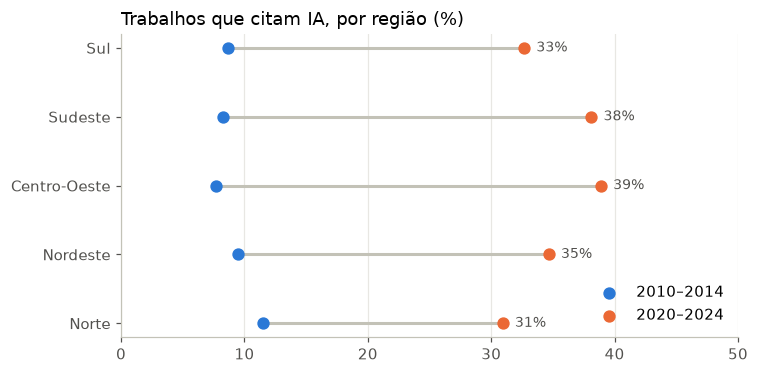

In [11]:
ordem = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
inicio_reg = trabalhos.query("ano <= 2014").groupby("regiao")["ia"].mean().reindex(ordem) * 100
fim_reg = trabalhos.query("ano >= 2020").groupby("regiao")["ia"].mean().reindex(ordem) * 100

fig, ax = plt.subplots(figsize=(7, 3.5))
y = np.arange(len(ordem))
ax.hlines(y, inicio_reg, fim_reg, color="#c3c2b7", linewidth=2)
ax.scatter(inicio_reg, y, color=AZUL, s=50, zorder=3, label="2010–2014")
ax.scatter(fim_reg, y, color=LARANJA, s=50, zorder=3, label="2020–2024")
for i, valor in enumerate(fim_reg):
    ax.annotate(f"{valor:.0f}%", (valor, i), xytext=(8, 0), textcoords="offset points",
                va="center", color=TINTA, fontsize=9)
ax.set_yticks(y, ordem)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True, color="#e8e7e3")
ax.set_xlim(0, 50)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Trabalhos que citam IA, por região (%)", loc="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURAS / "ia_por_regiao.png", bbox_inches="tight")